# code_058 · Aggregates and history summaries

**Book:** section 12.2. A self-contained feature-engineering laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_12_GUIDE.md), [run evidence](../CHAPTER_12_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_058).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose representation assumptions, fitting boundaries and operational constraints without field-validity, causal or universal feature-selection claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1258;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1258


<a id="clock"></a>
## Build features only from completed, arrived history

Six members have one 64-sample acceleration window per day for ten days, at 64 Hz. Their signals combine 4-Hz and 9-Hz sine components plus noise .03 mm/s². Every window ends at day+.2 and ordinarily arrives at day+.3. One member-0 day-6 window arrives only on day 9. Prediction cutoff is day 7.5; the trailing interval is (4.5,7.5]. Require both window end and arrival <=cutoff. Events observed before cutoff but arriving later are unavailable.

Inspection events for each member occur on days 1,5,8 and arrive 1.5,8,8.4. At cutoff 7.5 only the first inspection is admitted. The future grade and late day-5 record are excluded. Generate a ring of declared physical neighbors; neighbor summaries use only those neighbors' individually available windows. Edges are not causal effects or statistical independence guarantees. These are deterministic construction audits, not fitted prediction scores.


In [2]:
import pandas as pd
fs=64.;t=np.arange(64)/fs;rows=[]
for member in range(6):
 for day in range(10):
  signal=(1+.1*member+.03*day)*np.sin(2*np.pi*4*t)+.3*np.sin(2*np.pi*9*t+.2*member)+rng.normal(0,.03,64)
  rows.append({'member':member,'day':day,'end':day+.2,'arrival':9. if member==0 and day==6 else day+.3,'signal':signal})
inspections=pd.DataFrame([{'member':m,'event':d,'arrival':a,'grade':g} for m in range(6) for d,a,g in [(1.,1.5,0),(5.,8.,1),(8.,8.4,2)]])
cutoff=7.5;neighbors={m:[(m-1)%6,(m+1)%6] for m in range(6)}
def summaries(records,inspection_table,cut=7.5):
 own={};result={}
 for m in range(6):
  admitted=[r for r in records if r['member']==m and cut-3<r['end']<=cut and r['arrival']<=cut]
  assert all(r['end']<=cut and r['arrival']<=cut for r in admitted)
  values=np.concatenate([r['signal'] for r in admitted]);rms=float(np.sqrt(np.mean(values**2)))
  # Uniform 64-sample windows permit a one-sided Parseval calculation.
  energy=[];band=[]
  for r in admitted:
   z=r['signal'];P=np.abs(np.fft.rfft(z))**2/len(z)**2;weights=np.full(len(P),2.);weights[[0,-1]]=1
   np.testing.assert_allclose(np.sum(weights*P),np.mean(z**2),rtol=1e-12)
   energy.append(float(np.sum(weights*P)));band.append(float(weights[4]*P[4]))
  past=inspection_table[(inspection_table.member==m)&(inspection_table.event<=cut)&(inspection_table.arrival<=cut)]
  result[m]={'available_windows':len(admitted),'RMS_mm_s2':rms,'mean_square_mm2_s4':float(np.mean(energy)),'four_Hz_band_mean_square':float(np.mean(band)),'prior_inspections':len(past),'days_since_latest_known_event':float(cut-past.event.max()) if len(past) else None,'last_window_end':float(max(r['end'] for r in admitted))};own[m]=rms
 for m in result:result[m]['neighbor_mean_available_RMS']=float(np.mean([own[j] for j in neighbors[m]]))
 return result
features=summaries(rows,inspections);assert features[0]['available_windows']==2 and all(features[m]['available_windows']==3 for m in range(1,6));assert all(f['prior_inspections']==1 for f in features.values())
# Add future records with arbitrarily huge values: lawful historical features cannot change.
future=rows+[{'member':m,'day':20,'end':20.2,'arrival':20.3,'signal':np.full(64,1e9)} for m in range(6)]
assert summaries(future,inspections)==features
RESULTS['features_at_cutoff']={str(k):v for k,v in features.items()};RESULTS['future_append_invariance']=True;RESULTS['delayed_window_excluded']={'member':0,'event_end':6.2,'arrival':9.}


<a id="availability"></a>
## Show unavailable proxies alongside lawful summaries

RMS has acceleration units. The averaged squared acceleration and spectral band contribution have squared units; they are signal mean-square summaries, not physical mechanical energy without mass/model assumptions. Fourier bins are exactly aligned here; different window lengths, sampling rates, tapering and leakage require a changed spectral contract. No future grade is used to compute a feature. A late report may eventually update an archive while remaining excluded from a historical replay.


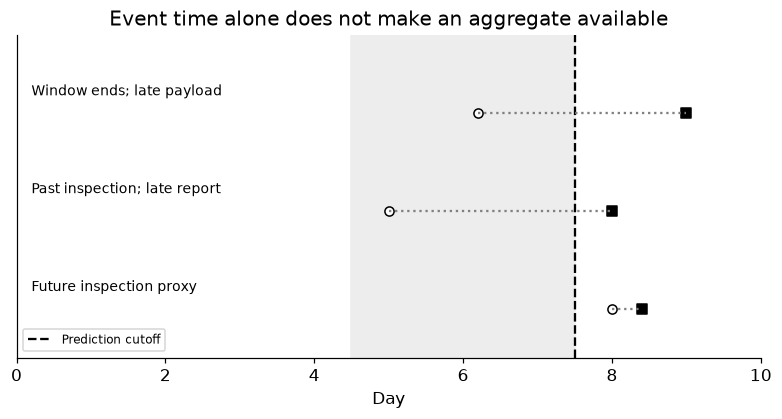

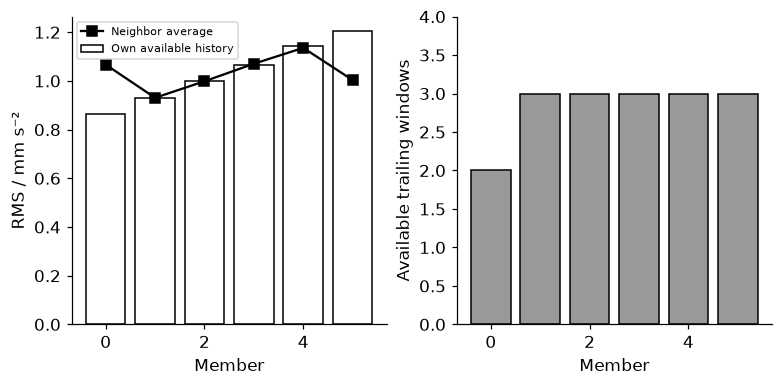

In [3]:
fig,ax=plt.subplots(figsize=(7,3.7));ax.axvspan(4.5,7.5,color='.93');ax.axvline(7.5,color='black',ls='--',label='Prediction cutoff')
for y0,event,arrival,label in [(3,6.2,9.,'Window ends; late payload'),(2,5.,8.,'Past inspection; late report'),(1,8.,8.4,'Future inspection proxy')]:
 ax.plot([event,arrival],[y0,y0],color='.5',ls=':');ax.scatter(event,y0,marker='o',facecolors='white',edgecolors='black');ax.scatter(arrival,y0,marker='s',color='black');ax.text(.2,y0+.18,label,fontsize=9)
ax.set(xlim=(0,10),ylim=(.5,3.8),yticks=[],xlabel='Day',title='Event time alone does not make an aggregate available');ax.legend(fontsize=8,loc='lower left');plt.show()
fig,axes=plt.subplots(1,2,figsize=(7,3.4));m=np.arange(6);axes[0].bar(m,[features[i]['RMS_mm_s2'] for i in m],color='white',edgecolor='black',label='Own available history');axes[0].plot(m,[features[i]['neighbor_mean_available_RMS'] for i in m],marker='s',color='black',label='Neighbor average');axes[0].set(xlabel='Member',ylabel='RMS / mm s⁻²');axes[0].legend(fontsize=7);axes[1].bar(m,[features[i]['available_windows'] for i in m],color='.6',edgecolor='black');axes[1].set(xlabel='Member',ylabel='Available trailing windows',ylim=(0,4));plt.show()


In [4]:
summary={'example_id':'code_058','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['event and arrival clocks in trailing windows', 'RMS and spectral energy summaries', 'prior inspection counts and recency', 'relational aggregates and future-append invariance'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["event and arrival clocks in trailing windows", "RMS and spectral energy summaries", "prior inspection counts and recency", "relational aggregates and future-append invariance"], "elapsed_seconds": 0.143, "example_id": "code_058", "hardware": "Darwin arm64 CPU", "results": {"delayed_window_excluded": {"arrival": 9.0, "event_end": 6.2, "member": 0}, "features_at_cutoff": {"0": {"RMS_mm_s2": 0.8634297245149338, "available_windows": 2, "days_since_latest_known_event": 6.5, "four_Hz_band_mean_square": 0.6990215038452515, "last_window_end": 7.2, "mean_square_mm2_s4": 0.7455108891759343, "neighbor_mean_available_RMS": 1.0667764815312548, "prior_inspections": 1}, "1": {"RMS_mm_s2": 0.9295959659866798, "available_windows": 3, "days_since_latest_known_event": 6.5, "four_Hz_band_mean_square": 0.8185569166373061, "last_window_end": 7.2, "mean_square_mm2_s4": 0.8641486599787083, "neighbor_mean_available_RMS": 0.9305266831425463, "prior_inspections"